Мета роботи:

Ознайомитися з базовим workflow задачі класифікації: від вибору та аналізу даних до навчання, налаштування, порівняння та оцінювання моделей машинного навчання з використанням бібліотеки Scikit-learn.

Завдання:

1) Завантаження та первинний аналіз даних: завантажити датасет; вивести назви колонок та розмір датасета; визначити ознаки (features) та цільову змінну (target); перевірити типи даних та розподіл об'єктів за класами.

2) Попередня обробка даних: перевірити наявність пропущених значень; за необхідності заповнити або видалити пропуски; якщо датасет містить категоріальні ознаки, виконати їх кодування; коротко пояснити прийняті рішення щодо попередньої обробки даних.

3) Візуалізація та дослідження даних - провести базовий Exploratory Data Analysis (EDA): побудувати heatmap кореляцій числових ознак; побудувати гістограми розподілу ознак; побудувати boxplot-и ознак відносно цільової змінної; коротко прокоментувати отримані візуалізації.
Якщо ознак багато, для візуалізації можна обмежитися декількома найбільш інформативними.

4) Підготовка даних до навчання: розділити дані на training та test вибірки; виконати масштабування/нормалізацію ознак для алгоритмів, для яких це необхідно.

5) Навчання моделей - навчити наступні класифікатори: 
k-Nearest Neighbors (kNN)
Decision Tree
Support Vector Machine (SVM)
Random Forest
AdaBoost

6) Підбір гіперпараметрів: для kNN підібрати оптимальне значення n_neighbors, для SVM за допомогою GridSearchCV підібрати оптимальні значення C та gamma. За бажанням можна дослідити вплив гіперпараметрів і для інших моделей.

7) Порівняння та оцінювання моделей
Порівняти результати всіх навчених класифікаторів та визначити найкращу модель для обраного датасета.

Для моделей вивести та проаналізувати:
sklearn.metrics.classification_report, 
sklearn.metrics.confusion_matrix

Зробити короткий висновок: яка модель показала найкращий результат і чому, на вашу думку, вона краще підходить для обраних даних.


### 1. Завантаження та первинний аналіз


In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

df = pd.read_csv(
    r"C:\Users\HP\Desktop\маг 1 курс\Аналіз\1\spotify-tracks-dataset.csv"
)

df.head()

,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [48]:
print("Розмір датасета:", df.shape)
print("\nНазви колонок:")
print(df.columns.tolist())

Розмір датасета: (114000, 22)

Назви колонок:
['Unnamed: 0.1', 'Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']


In [49]:
df = df.drop(columns=["Unnamed: 0.1", "Unnamed: 0"])


In [50]:
print("Розмір датасета:", df.shape)
print("\nНазви колонок:")
print(df.columns.tolist())

Розмір датасета: (114000, 20)

Назви колонок:
['track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']


In [51]:
print("\nТипи даних:")
print(df.dtypes)


Типи даних:
track_id             object
artists              object
album_name           object
track_name           object
popularity            int64
duration_ms           int64
explicit               bool
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
time_signature        int64
track_genre          object
dtype: object


In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          114000 non-null  object 
 1   artists           113999 non-null  object 
 2   album_name        113999 non-null  object 
 3   track_name        113999 non-null  object 
 4   popularity        114000 non-null  int64  
 5   duration_ms       114000 non-null  int64  
 6   explicit          114000 non-null  bool   
 7   danceability      114000 non-null  float64
 8   energy            114000 non-null  float64
 9   key               114000 non-null  int64  
 10  loudness          114000 non-null  float64
 11  mode              114000 non-null  int64  
 12  speechiness       114000 non-null  float64
 13  acousticness      114000 non-null  float64
 14  instrumentalness  114000 non-null  float64
 15  liveness          114000 non-null  float64
 16  valence           11

In [53]:
# 0 — непопулярний, 1 — популярний
df["target"] = (df["popularity"] >= 50).astype(int)

print("Розподіл об'єктів за класами:")
print(df["target"].value_counts())

print("\nРозподіл у відсотках:")
print(df["target"].value_counts(normalize=True) * 100)

Розподіл об'єктів за класами:
target
0    84633
1    29367
Name: count, dtype: int64

Розподіл у відсотках:
target
0    74.239474
1    25.760526
Name: proportion, dtype: float64


У датасеті початково немає готової цільової змінної для задачі бінарної класифікації. Тому її було сформовано на основі показника `popularity`.

Трек вважається непопулярним (`target = 0`), якщо його значення `popularity` менше 50, та популярним (`target = 1`), якщо `popularity` не менше 50.

Таким чином, задача класифікації полягає у визначенні того, чи є трек популярним, використовуючи його аудіохарактеристики.

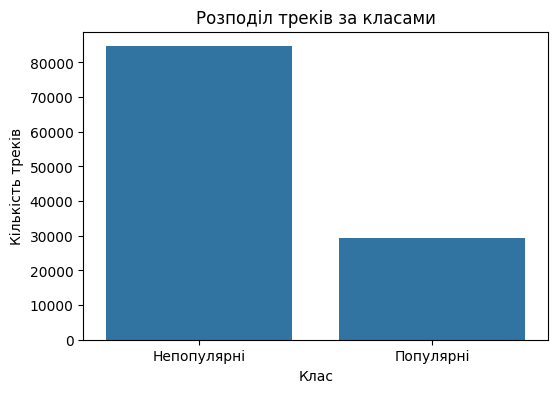

In [54]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="target")

plt.title("Розподіл треків за класами")
plt.xlabel("Клас")
plt.ylabel("Кількість треків")
plt.xticks([0, 1], ["Непопулярні", "Популярні"])

plt.show()

In [55]:
features = [
    "duration_ms",
    "explicit",
    "danceability",
    "energy",
    "key",
    "loudness",
    "mode",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "time_signature"
]

X = df[features]
y = df["target"]

print("Ознаки:")
print(features)

print("\nЦільова змінна:")
print("target")

print("\nРозмір X:", X.shape)
print("Розмір y:", y.shape)

Ознаки:
['duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']

Цільова змінна:
target

Розмір X: (114000, 14)
Розмір y: (114000,)


### 2. Попередня обробка даних


In [56]:
missing_values = df.isnull().sum()

print("Пропущені значення:")
print(missing_values)

Пропущені значення:
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
target              0
dtype: int64


In [57]:
df = df.dropna()

print("Розмір датасета після видалення пропусків:", df.shape)
print("Загальна кількість пропущених значень:", df.isnull().sum().sum())

Розмір датасета після видалення пропусків: (113999, 21)
Загальна кількість пропущених значень: 0


In [58]:
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 450


In [59]:
print("Категоріальні колонки:")
print(df.select_dtypes(include=["object"]).columns.tolist())

Категоріальні колонки:
['track_id', 'artists', 'album_name', 'track_name', 'track_genre']



Спочатку було перевірено датасет на наявність пропущених значень. 
Пропуски були виявлені у трьох колонках: `artists`, `album_name` та 
`track_name`. Оскільки ці колонки не використовуються як ознаки для 
навчання моделей, а кількість рядків із пропусками є незначною, 
такі рядки було видалено.

Після видалення пропусків у датасеті відсутні пропущені значення.

Також було визначено категоріальні колонки: `track_id`, `artists`, 
`album_name`, `track_name` та `track_genre`. Для побудови моделей 
вони не використовуються, оскільки метою роботи є класифікація 
популярності треків за їхніми числовими аудіохарактеристиками. 
Тому додаткове кодування категоріальних ознак не проводилося.

Для навчання моделей використовуються числові та бінарні ознаки:
`duration_ms`, `explicit`, `danceability`, `energy`, `key`, 
`loudness`, `mode`, `speechiness`, `acousticness`, 
`instrumentalness`, `liveness`, `valence`, `tempo` та `time_signature`.

Таким чином, після попередньої обробки для навчання моделей залишено 14 числових 
та бінарних ознак. Категоріальні текстові ознаки не використовувалися, тому їх кодування не є необхідним.

### 3. Візуалізація та дослідження даних

In [60]:
selected_features = [
    "danceability",
    "energy",
    "loudness",
    "acousticness",
    "instrumentalness",
    "valence",
    "tempo"
]

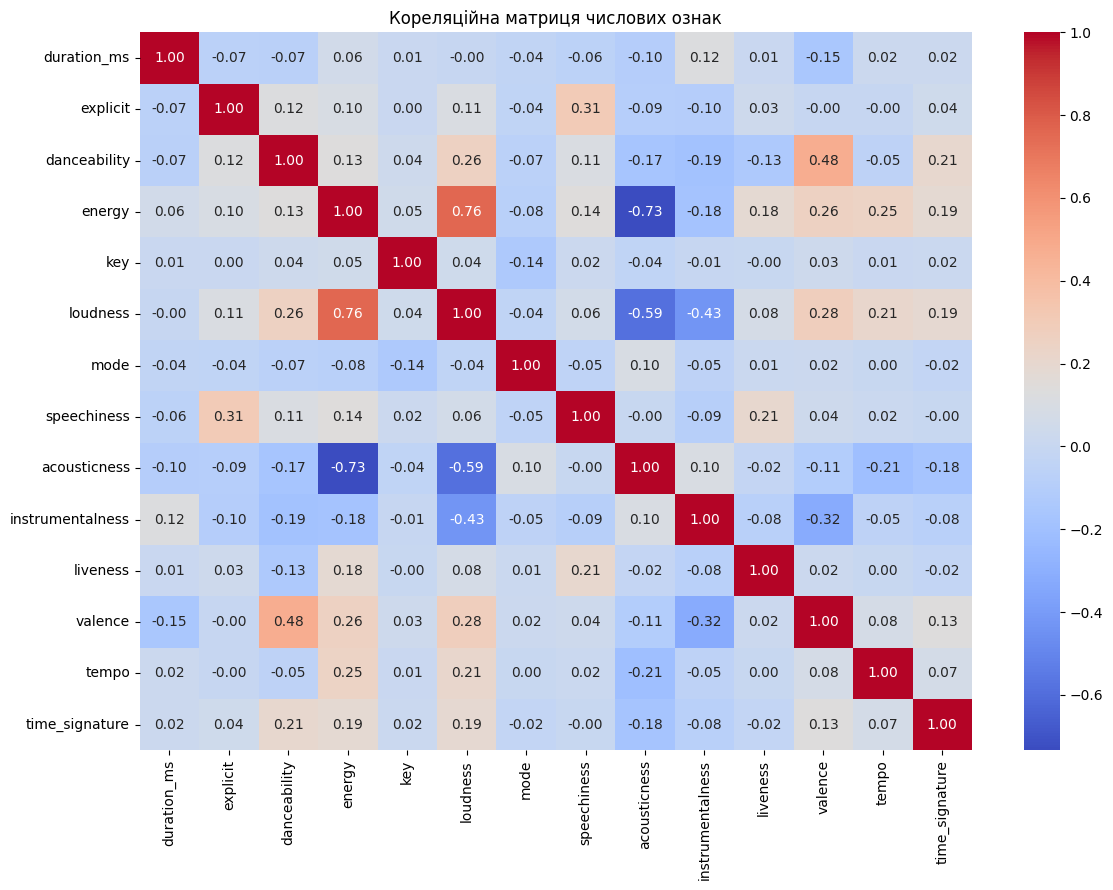

In [61]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    X.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Кореляційна матриця числових ознак")
plt.tight_layout()
plt.show()

Кореляційна матриця показує силу лінійного зв'язку між числовими ознаками. Найбільш помітною є кореляція між `energy` та `loudness`, оскільки енергетичні треки зазвичай мають вищу гучність. Більшість інших ознак мають слабкі або помірні кореляційні зв'язки.

Отже, між більшістю ознак немає сильної лінійної залежності, тому вони можуть містити додаткову інформацію для моделей класифікації.

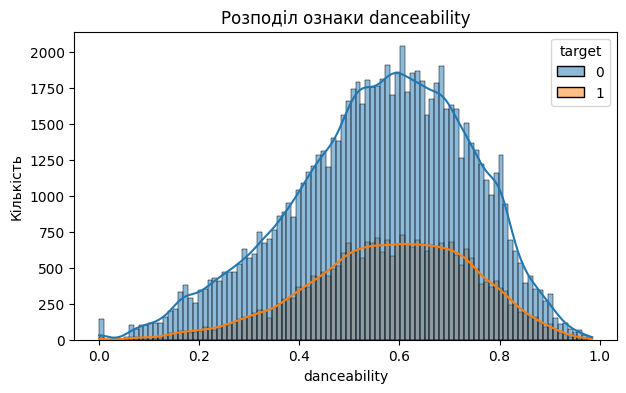

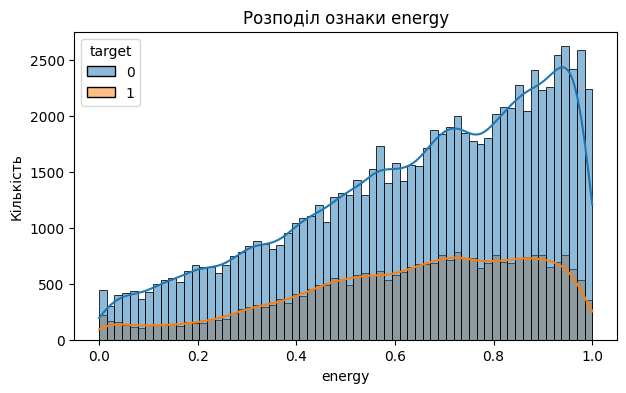

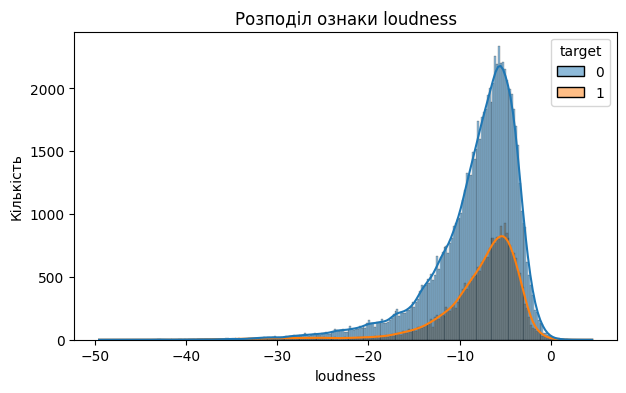

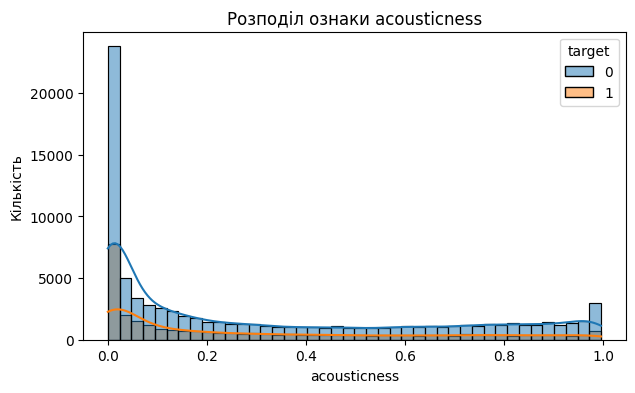

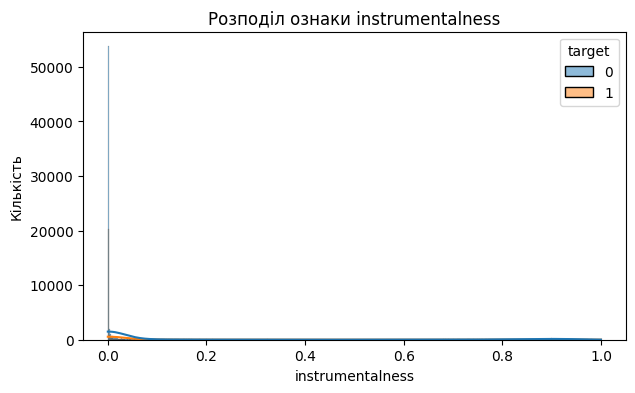

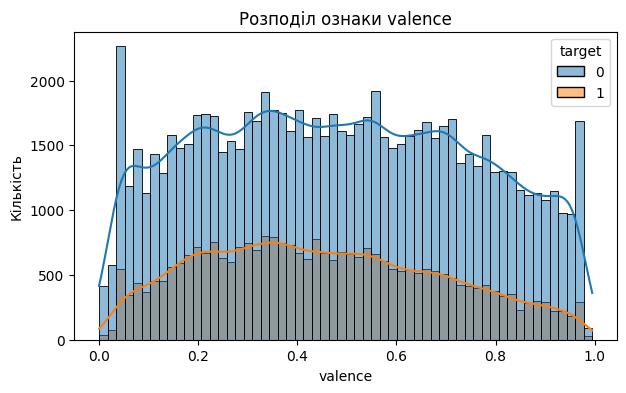

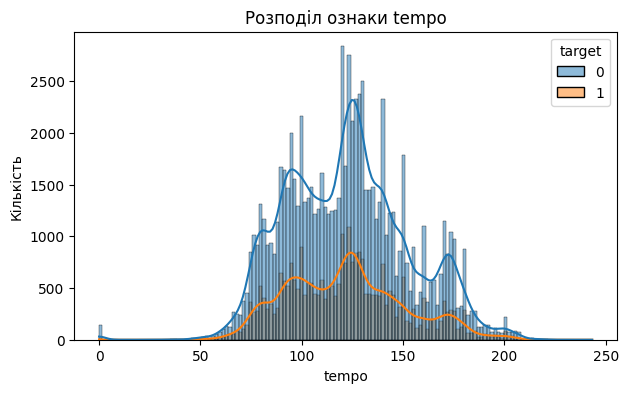

In [62]:
for feature in selected_features:
    plt.figure(figsize=(7, 4))

    sns.histplot(
        data=df,
        x=feature,
        hue="target",
        kde=True
    )

    plt.title(f"Розподіл ознаки {feature}")
    plt.xlabel(feature)
    plt.ylabel("Кількість")

    plt.show()

Гістограми демонструють розподіл вибраних аудіохарактеристик для популярних та непопулярних треків. Для деяких ознак розподіли двох класів частково відрізняються, однак у більшості випадків вони суттєво перекриваються.

Це означає, що окремої ознаки недостатньо для надійного визначення популярності треку, тому для класифікації доцільно використовувати сукупність характеристик.

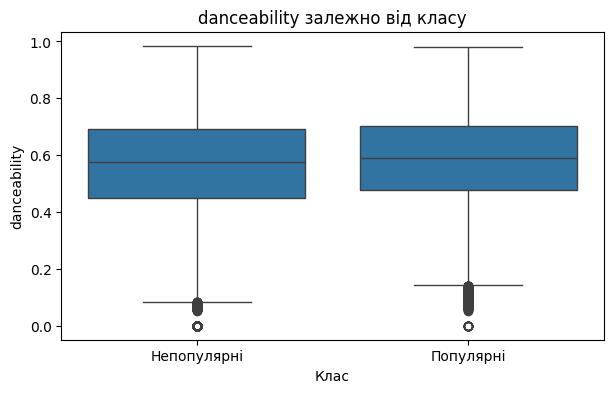

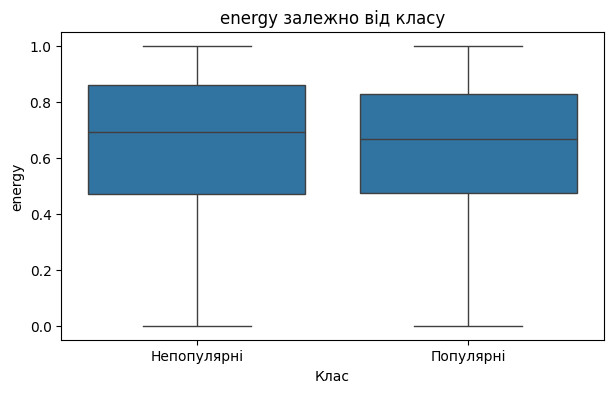

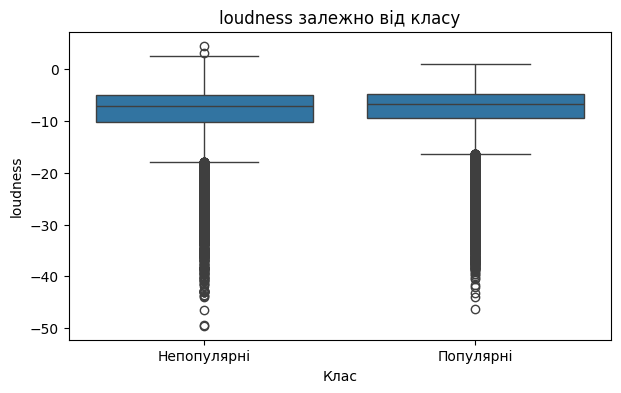

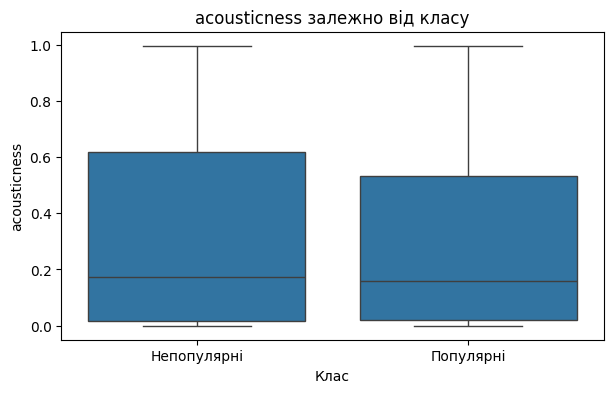

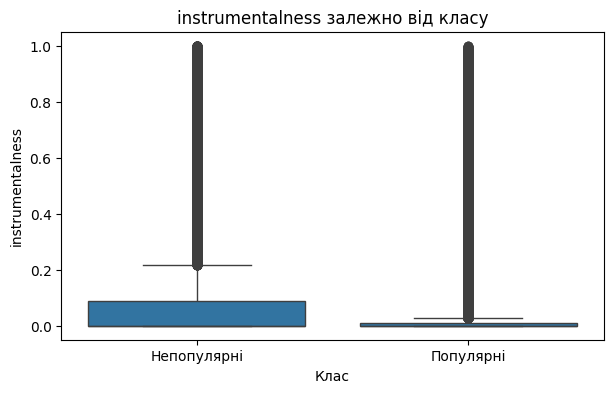

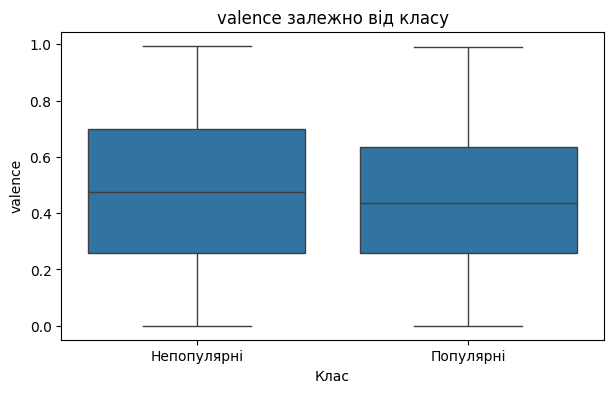

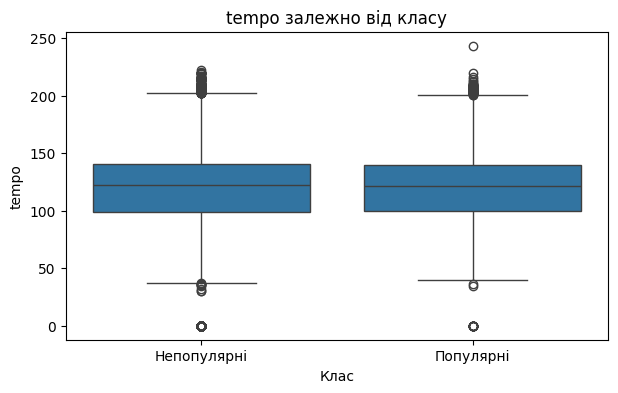

In [63]:
for feature in selected_features:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x="target",
        y=feature
    )

    plt.title(f"{feature} залежно від класу")
    plt.xlabel("Клас")
    plt.ylabel(feature)
    plt.xticks([0, 1], ["Непопулярні", "Популярні"])

    plt.show()

Boxplot-и дозволяють порівняти медіани та розкид значень ознак для двох класів. Для окремих характеристик спостерігаються відмінності між популярними та непопулярними треками, проте значне перекриття розподілів зберігається.

Отже, класи не є повністю відокремленими в просторі окремих ознак, що пояснює необхідність використання моделей машинного навчання для пошуку складніших залежностей.

### 4. Підготовка даних до навчання

In [64]:
X_sample, _, y_sample, _ = train_test_split(
    X,
    y,
    train_size=20000,
    random_state=42,
    stratify=y
)

print("Розмір підвибірки:", X_sample.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X_sample,
    y_sample,
    test_size=0.2,
    random_state=42,
    stratify=y_sample
)

print("Розмір training-вибірки:", X_train.shape)
print("Розмір test-вибірки:", X_test.shape)


Розмір підвибірки: (20000, 14)
Розмір training-вибірки: (16000, 14)
Розмір test-вибірки: (4000, 14)


In [65]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Масштабування виконано.")

Масштабування виконано.



Початковий датасет містить 114 000 об'єктів. Для навчання моделей було сформовано  підвибірку з 20 000 об'єктів.

Такий підхід використано для зменшення обчислювального навантаження, насамперед під час навчання SVM та виконання GridSearchCV. Параметр `stratify=y` забезпечує збереження приблизно такого самого співвідношення класів, як і в початковому датасеті.

Після цього підвибірку було розділено на training та test у співвідношенні 80% / 20%.

### 5. Навчання моделей

In [66]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled, y_train)

print("kNN навчено.")

kNN навчено.


In [67]:
decision_tree = DecisionTreeClassifier(
    random_state=42
)

decision_tree.fit(X_train, y_train)

print("Decision Tree навчено.")

Decision Tree навчено.


In [68]:
svm = SVC()

svm.fit(X_train_scaled, y_train)

print("SVM навчено.")

SVM навчено.


In [69]:
random_forest = RandomForestClassifier(
    random_state=42
)

random_forest.fit(X_train, y_train)

print("Random Forest навчено.")

Random Forest навчено.


In [70]:
adaboost = AdaBoostClassifier(
    random_state=42
)

adaboost.fit(X_train, y_train)

print("AdaBoost навчено.")

c:\Users\HP\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


AdaBoost навчено.


### 6. Підбір гіперпараметрів

In [71]:
param_grid_knn = {
    "n_neighbors": [3, 5, 7, 9, 11]
}

grid_knn = GridSearchCV(
    KNeighborsClassifier(),
    param_grid_knn,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

grid_knn.fit(X_train_scaled, y_train)

print("Найкраще n_neighbors:", grid_knn.best_params_)
print("Найкраща accuracy:", grid_knn.best_score_)

Найкраще n_neighbors: {'n_neighbors': 11}
Найкраща accuracy: 0.7258750330125855


In [72]:
best_knn = grid_knn.best_estimator_

In [73]:
param_grid_svm = {
    "C": [0.1, 1, 10],
    "gamma": ["scale", 0.01, 0.1]
}

grid_svm = GridSearchCV(
    SVC(kernel="rbf"),
    param_grid_svm,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

grid_svm.fit(X_train_scaled, y_train)

print("Найкращі параметри SVM:", grid_svm.best_params_)
print("Найкраща accuracy:", grid_svm.best_score_)

Найкращі параметри SVM: {'C': 1, 'gamma': 0.1}
Найкраща accuracy: 0.7444374394134542


In [74]:
best_svm = grid_svm.best_estimator_


Для kNN було досліджено декілька значень `n_neighbors`: 3, 5, 7, 9 та 11. Оптимальним вважається значення, яке забезпечило найбільшу середню accuracy на крос-валідації.

Для SVM за допомогою `GridSearchCV` було досліджено різні комбінації параметрів `C` та `gamma`. Найкращою вважається комбінація, яка дала найвищу середню accuracy на крос-валідації.

Для kNN я взяла невеликі непарні значення кількості сусідів, щоб перевірити кілька рівнів локальності моделі та уникнути нічиєї під час голосування. Для SVM взяла значення C і gamma, що охоплюють низький, середній та вищий рівні регуляризації й складності моделі. Це не фіксовані правильні значення — GridSearchCV вибирає найкращу комбінацію з дослідженого набору.

### 7. Оцінювання та порівняння моделей

In [75]:
y_pred_knn = best_knn.predict(X_test_scaled)
y_pred_svm = best_svm.predict(X_test_scaled)
y_pred_tree = decision_tree.predict(X_test)
y_pred_rf = random_forest.predict(X_test)
y_pred_adaboost = adaboost.predict(X_test)

In [76]:
print("===== kNN =====")
print(classification_report(y_test, y_pred_knn))

print("===== SVM =====")
print(classification_report(y_test, y_pred_svm))

print("===== Decision Tree =====")
print(classification_report(y_test, y_pred_tree))

print("===== Random Forest =====")
print(classification_report(y_test, y_pred_rf))

print("===== AdaBoost =====")
print(classification_report(y_test, y_pred_adaboost))

===== kNN =====
              precision    recall  f1-score   support

           0       0.76      0.92      0.83      2970
           1       0.40      0.16      0.23      1030

    accuracy                           0.72      4000
   macro avg       0.58      0.54      0.53      4000
weighted avg       0.67      0.72      0.67      4000

===== SVM =====
              precision    recall  f1-score   support

           0       0.75      0.99      0.85      2970
           1       0.67      0.03      0.06      1030

    accuracy                           0.75      4000
   macro avg       0.71      0.51      0.46      4000
weighted avg       0.73      0.75      0.65      4000

===== Decision Tree =====
              precision    recall  f1-score   support

           0       0.79      0.79      0.79      2970
           1       0.40      0.40      0.40      1030

    accuracy                           0.69      4000
   macro avg       0.59      0.59      0.59      4000
weighted avg    

In [77]:
results = {
    "kNN": accuracy_score(y_test, y_pred_knn),
    "SVM": accuracy_score(y_test, y_pred_svm),
    "Decision Tree": accuracy_score(y_test, y_pred_tree),
    "Random Forest": accuracy_score(y_test, y_pred_rf),
    "AdaBoost": accuracy_score(y_test, y_pred_adaboost)
}

results_df = pd.DataFrame(
    list(results.items()),
    columns=["Модель", "Accuracy"]
).sort_values(
    by="Accuracy",
    ascending=False
)

print(results_df)

          Модель  Accuracy
3  Random Forest   0.77050
1            SVM   0.74675
4       AdaBoost   0.73750
0            kNN   0.72175
2  Decision Tree   0.68850


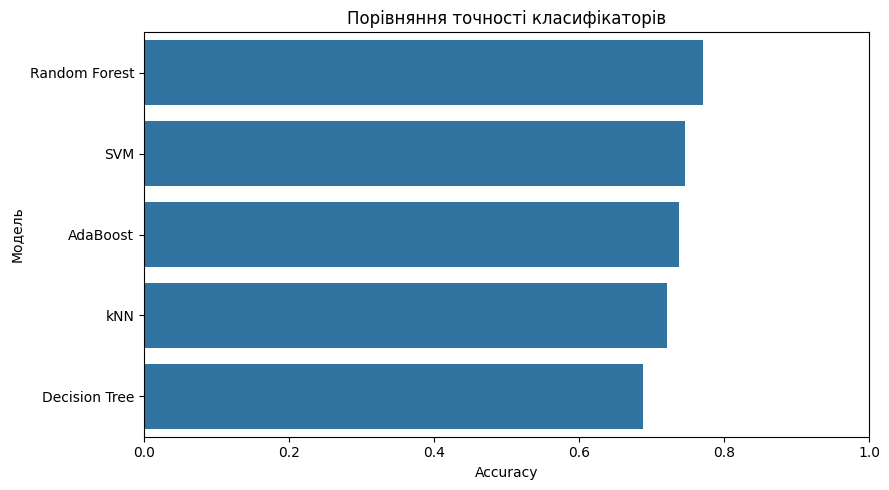

In [78]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Accuracy",
    y="Модель"
)

plt.xlim(0, 1)
plt.title("Порівняння точності класифікаторів")
plt.xlabel("Accuracy")
plt.ylabel("Модель")
plt.tight_layout()
plt.show()

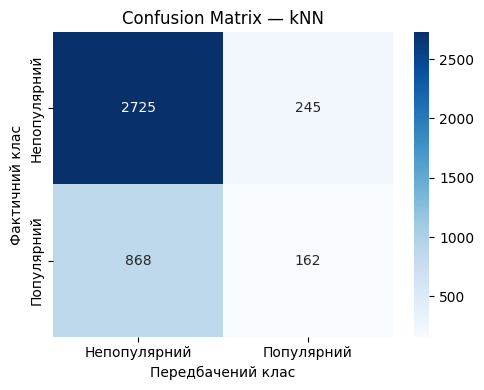

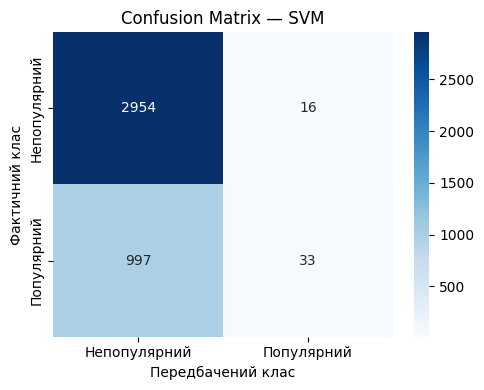

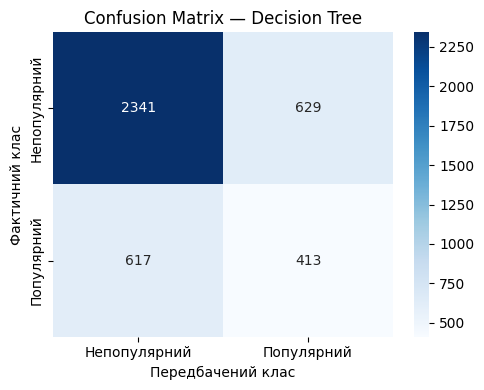

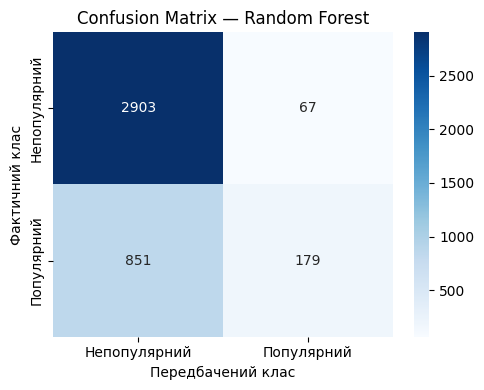

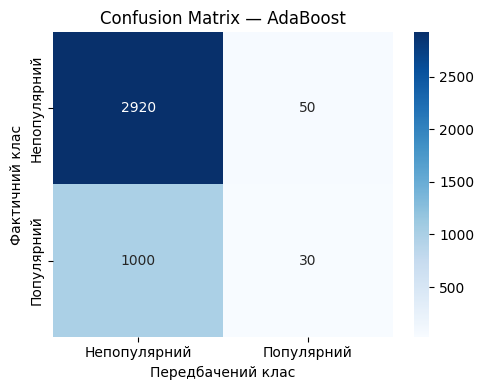

In [79]:
predictions = {
    "kNN": y_pred_knn,
    "SVM": y_pred_svm,
    "Decision Tree": y_pred_tree,
    "Random Forest": y_pred_rf,
    "AdaBoost": y_pred_adaboost
}

for name, y_pred in predictions.items():
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Непопулярний", "Популярний"],
        yticklabels=["Непопулярний", "Популярний"]
    )

    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Передбачений клас")
    plt.ylabel("Фактичний клас")
    plt.tight_layout()
    plt.show()

Для оцінювання якості роботи моделей було використано `classification_report`, який містить значення precision, recall та F1-score для кожного класу, а також загальну accuracy моделі.

Для порівняння п'яти класифікаторів було сформовано зведену таблицю та побудовано графік значень accuracy. Це дозволяє визначити модель, яка показала найкращий результат на тестовій вибірці.

Матриця помилок показує кількість правильних та неправильних класифікацій для кожного класу. Елементи головної діагоналі відповідають правильно класифікованим трекам, а позадіагональні елементи — помилкам класифікації.

Порівнюючи отримані матриці, можна оцінити, наскільки добре кожна модель розпізнає популярні та непопулярні треки. Для вибору найкращої моделі враховувалися не лише загальна accuracy, а й показники precision, recall та F1-score для обох класів.



### 8. Висновки

In [80]:
best_model = results_df.iloc[0]["Модель"]
best_accuracy = results_df.iloc[0]["Accuracy"]

print(f"Найкраща модель: {best_model}")
print(f"Accuracy: {best_accuracy:.4f}")

Найкраща модель: Random Forest
Accuracy: 0.7705


У роботі було розглянуто задачу бінарної класифікації музичних треків за їхніми аудіохарактеристиками. Було виконано первинний аналіз даних, попередню обробку, EDA, поділ даних на training та test вибірки та масштабування ознак для алгоритмів, чутливих до масштабу.

Було навчено п'ять моделей класифікації: kNN, Decision Tree, SVM, Random Forest та AdaBoost. Для kNN було виконано підбір параметра `n_neighbors`, а для SVM — підбір параметрів `C` та `gamma` за допомогою `GridSearchCV`.

За результатами тестування найкращою виявилася модель Random Forest, яка отримала найвище значення accuracy — 0.7705.

Отриманий результат можна пояснити тим, що ця модель краще враховує складні залежності між аудіохарактеристиками треків та їхньою популярністю. Водночас результати confusion matrix показують, наскільки добре модель розпізнає кожен із двох класів.

Отже, обрана модель є найбільш придатною серед досліджених алгоритмів для класифікації популярності треків у цьому датасеті.